# MLOps Assignment 01 — Heart Disease Prediction

**Problem:** Build, track, package, test, containerize, deploy, and monitor a binary classifier for the UCI Cleveland Heart Disease dataset.

> Run the notebook from top to bottom in Google Colab or a local Python environment. The notebook creates a `heart-disease-mlops/` project folder with source code, model artifacts, tests, CI/CD configuration, Docker/Kubernetes files, and documentation. Cloud deployment credentials and screenshots must be supplied by the student; they cannot be fabricated by a notebook.

## Task 1 — Data acquisition, cleaning, and EDA
The source is the UCI Machine Learning Repository's Cleveland processed dataset. The original target `num` ranges from 0–4; this project maps `num > 0` to class 1 (heart disease present), otherwise class 0. Missing feature values are retained until the train-fitted preprocessing pipeline imputes them, avoiding data leakage.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from io import StringIO
import json, os, sys, subprocess, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
PROJECT_DIR = Path.cwd() / "heart-disease-mlops"
for folder in ["data/raw", "data/processed", "reports/figures", "models",
               "src", "tests", ".github/workflows", "deployment"]:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
       "heart-disease/processed.cleveland.data")
columns = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach",
           "exang","oldpeak","slope","ca","thal","num"]

try:
    with urlopen(URL, timeout=30) as response:
        raw_text = response.read().decode("utf-8")
except Exception as exc:
    raise RuntimeError(
        "Could not download the UCI dataset. Check internet access and rerun. "
        f"Source: {URL}. Error: {exc}"
    ) from exc

df_raw = pd.read_csv(StringIO(raw_text), header=None, names=columns,
                     na_values="?", skipinitialspace=True)
df_raw.to_csv(PROJECT_DIR / "data/raw/heart_disease_raw.csv", index=False)

df = df_raw.apply(pd.to_numeric, errors="coerce").drop_duplicates().copy()
df = df.dropna(subset=["num"])
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")
CLEAN_FILE = PROJECT_DIR / "data/processed/heart_disease_clean.csv"
df.to_csv(CLEAN_FILE, index=False)

numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
feature_columns = numeric_features + categorical_features

print("Raw shape:", df_raw.shape, "| Clean shape:", df.shape)
print("Features:", len(feature_columns))
print("Missing values by feature:\n", df[feature_columns].isna().sum())
print("Target counts:\n", df["target"].value_counts().sort_index())
print("Saved:", CLEAN_FILE)
display(df.head())

Raw shape: (303, 14) | Clean shape: (303, 14)
Features: 13
Missing values by feature:
 age         0
trestbps    0
chol        0
thalach     0
oldpeak     0
sex         0
cp          0
fbs         0
restecg     0
exang       0
slope       0
ca          4
thal        2
dtype: int64
Target counts:
 target
0    164
1    139
Name: count, dtype: int64
Saved: /content/heart-disease-mlops/data/processed/heart_disease_clean.csv


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


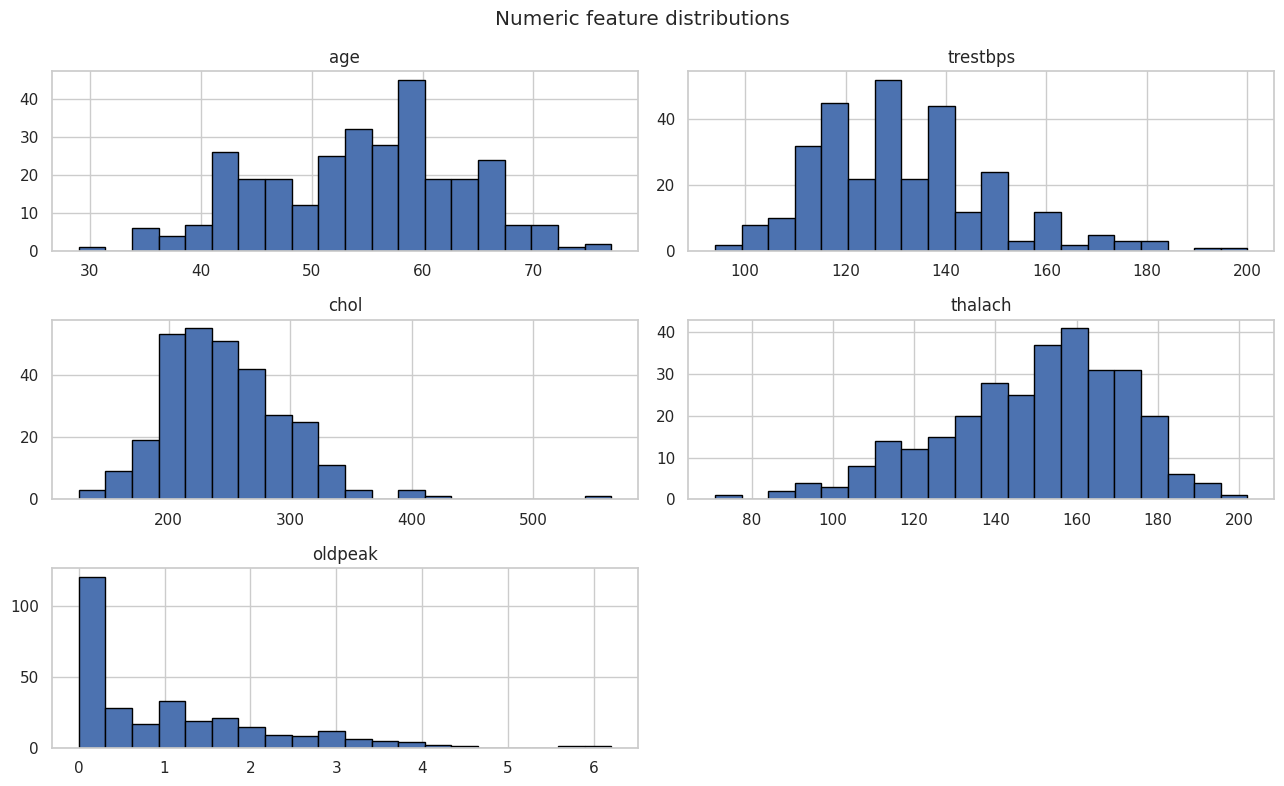

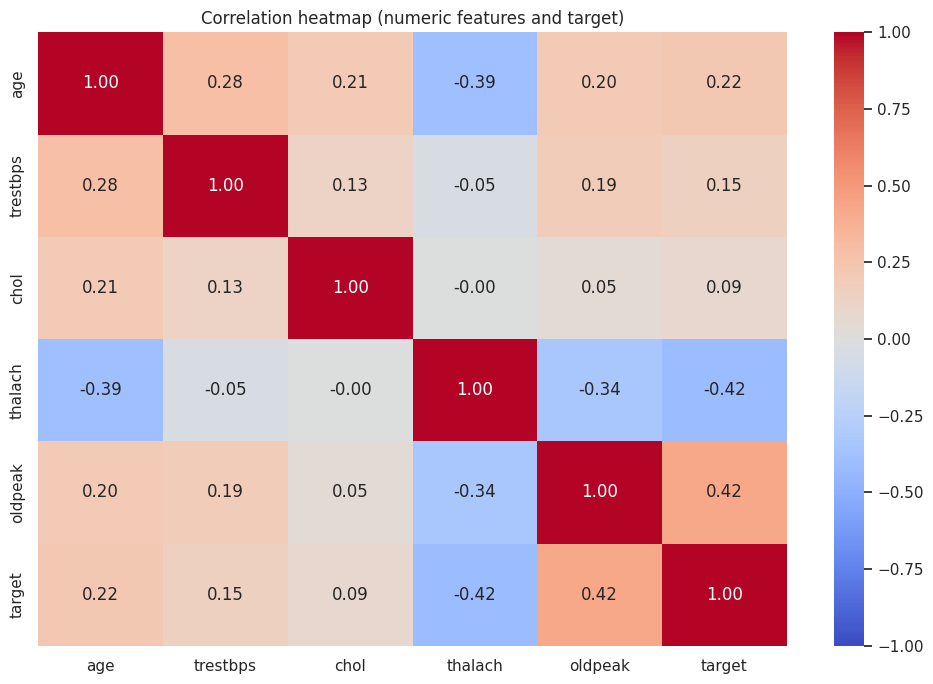

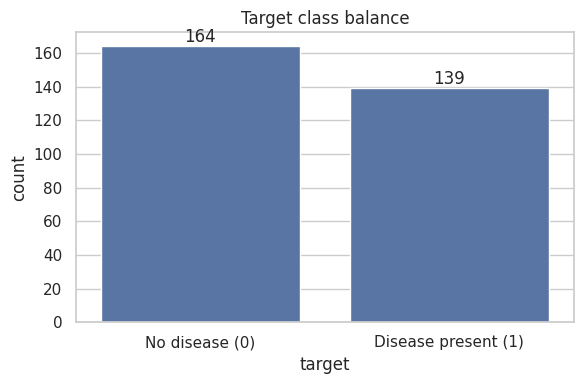

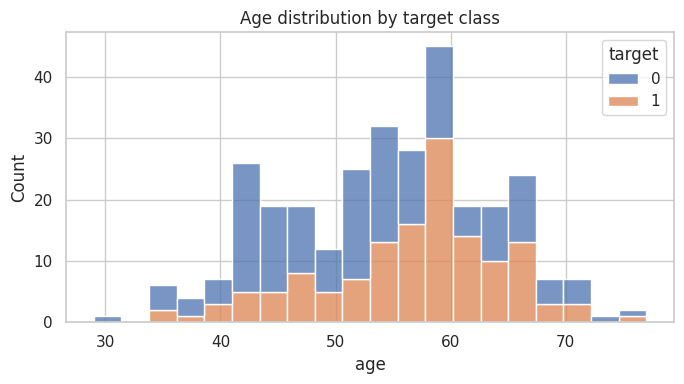

Task 1 checks passed.


In [2]:
sns.set_theme(style="whitegrid")
FIG_DIR = PROJECT_DIR / "reports/figures"

df[numeric_features].hist(figsize=(13, 8), bins=20, edgecolor="black")
plt.suptitle("Numeric feature distributions")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_histograms.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_features + ["target"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap (numeric features and target)")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="target")
ax.set_xticks([0, 1], ["No disease (0)", "Disease present (1)"])
ax.set_title("Target class balance")
for container in ax.containers: ax.bar_label(container)
plt.tight_layout()
plt.savefig(FIG_DIR / "class_balance.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", hue="target", bins=20, multiple="stack")
plt.title("Age distribution by target class")
plt.tight_layout()
plt.savefig(FIG_DIR / "age_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

assert not df.empty and df["target"].notna().all()
assert set(df["target"].unique()) == {0, 1}
assert len(feature_columns) == len(df.columns) - 1
print("Task 1 checks passed.")

### Task 1 interpretation
- Histograms show the distributions and potential skew/outliers in numerical measurements.
- The heatmap shows pairwise linear correlations, not causal relationships.
- Class balance must be considered when interpreting accuracy; recall and ROC-AUC are also reported.
- The Cleveland dataset is small and historically collected. It is educational and is not suitable for clinical decision-making.

## Task 2 — Feature engineering, model development, tuning, and evaluation
Preprocessing is part of each `Pipeline`: numeric values are median-imputed and standardized; categorical values are most-frequent-imputed and one-hot encoded. Since the pipeline is fitted separately within each CV fold, imputation/scaling/encoding do not leak information from validation folds. Two classifiers are compared: Logistic Regression and Random Forest.

In [3]:
%pip -q install pandas numpy scikit-learn matplotlib seaborn joblib mlflow fastapi uvicorn pytest httpx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 40.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.

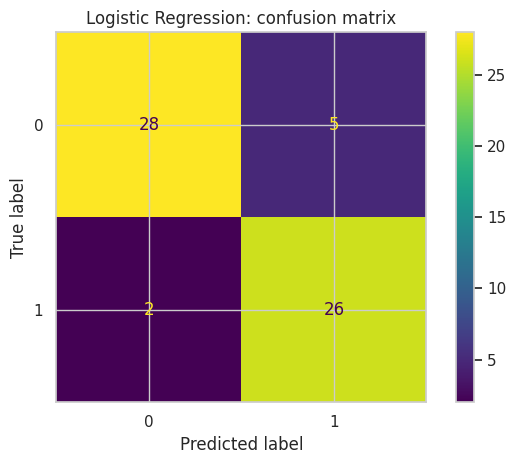

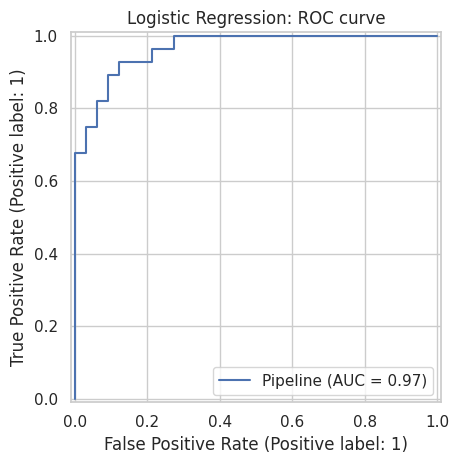


 Logistic Regression 
               precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



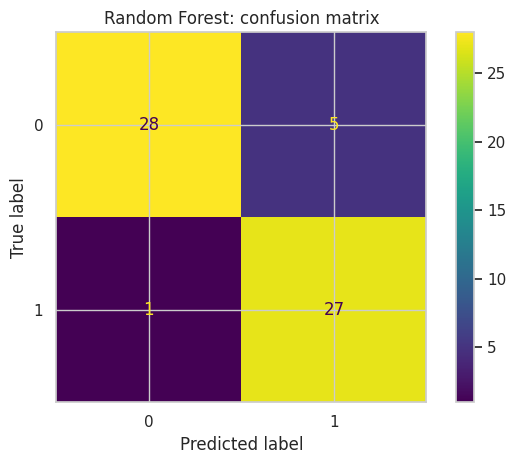

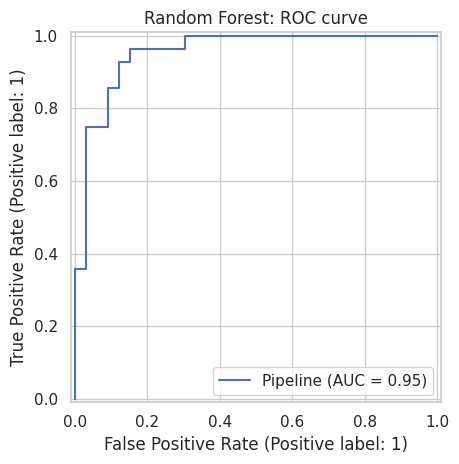


 Random Forest 
               precision    recall  f1-score   support

           0       0.97      0.85      0.90        33
           1       0.84      0.96      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.91      0.90        61
weighted avg       0.91      0.90      0.90        61



,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.90279,{'classifier__C': 0.1}
1,Random Forest,0.90161,"{'classifier__max_depth': 10, 'classifier__min..."


,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,0.8304,0.0168,0.8232,0.0435,0.8099,0.0680,0.8132,0.0230,0.9028,0.0169
1,Random Forest,0.8055,0.0296,0.7921,0.0528,0.7917,0.0946,0.7865,0.0408,0.9016,0.0297


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9654
1,Random Forest,0.9016,0.8438,0.9643,0.9000,0.9535


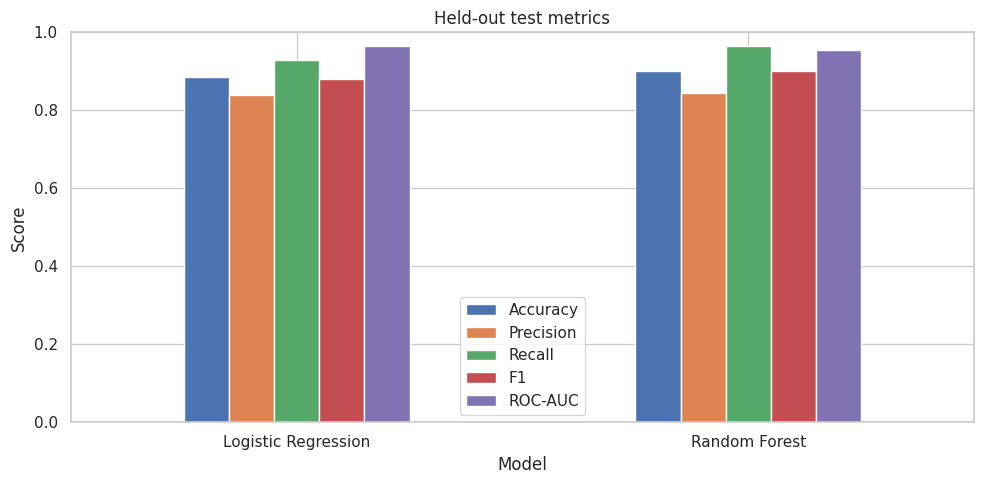

Selected model: Logistic Regression | saved: /content/heart-disease-mlops/models/heart_disease_pipeline.joblib


In [4]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay)

X = df[feature_columns].copy()
y = df["target"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=SEED),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=SEED,
                                             n_jobs=-1)
}
param_grids = {
    "Logistic Regression": {"classifier__C": [0.1, 1.0, 10.0]},
    "Random Forest": {"classifier__n_estimators": [100, 200],
                      "classifier__max_depth": [None, 5, 10],
                      "classifier__min_samples_leaf": [1, 2]}
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy":"accuracy", "precision":"precision", "recall":"recall",
           "f1":"f1", "roc_auc":"roc_auc"}

tuned_models, tuning_rows, cv_rows, test_rows = {}, [], [], []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", make_preprocessor()), ("classifier", estimator)])
    search = GridSearchCV(pipe, param_grids[name], scoring="roc_auc", cv=cv,
                          n_jobs=-1, refit=True, error_score="raise")
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    tuning_rows.append({"Model": name, "Best CV ROC-AUC": search.best_score_,
                        "Best Parameters": str(search.best_params_)})
    scores = cross_validate(search.best_estimator_, X_train, y_train, cv=cv,
                            scoring=scoring, n_jobs=-1, error_score="raise")
    row = {"Model": name}
    for metric in scoring:
        row[f"{metric}_mean"] = float(scores[f"test_{metric}"].mean())
        row[f"{metric}_std"] = float(scores[f"test_{metric}"].std())
    cv_rows.append(row)

    pred = search.best_estimator_.predict(X_test)
    prob = search.best_estimator_.predict_proba(X_test)[:, 1]
    test_rows.append({"Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)})
    safe = name.lower().replace(" ", "_")
    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title(f"{name}: confusion matrix"); plt.tight_layout()
    plt.savefig(FIG_DIR / f"{safe}_confusion_matrix.png", dpi=200); plt.show(); plt.close()
    RocCurveDisplay.from_estimator(search.best_estimator_, X_test, y_test)
    plt.title(f"{name}: ROC curve"); plt.tight_layout()
    plt.savefig(FIG_DIR / f"{safe}_roc_curve.png", dpi=200); plt.show(); plt.close()
    print("\n", name, "\n", classification_report(y_test, pred, zero_division=0))

tuning_df = pd.DataFrame(tuning_rows)
cv_results_df = pd.DataFrame(cv_rows)
test_results_df = pd.DataFrame(test_rows)
display(tuning_df)
display(cv_results_df.round(4))
display(test_results_df.round(4))

# Select by mean CV ROC-AUC, then refit the selected pipeline on the training split.
best_name = cv_results_df.loc[cv_results_df["roc_auc_mean"].idxmax(), "Model"]
best_model = tuned_models[best_name]
model_path = PROJECT_DIR / "models/heart_disease_pipeline.joblib"
joblib.dump(best_model, model_path)

tuning_df.to_csv(PROJECT_DIR / "reports/hyperparameter_tuning_results.csv", index=False)
cv_results_df.to_csv(PROJECT_DIR / "reports/cross_validation_results.csv", index=False)
test_results_df.to_csv(PROJECT_DIR / "reports/test_results.csv", index=False)
test_results_df.set_index("Model")[["Accuracy","Precision","Recall","F1","ROC-AUC"]].plot(
    kind="bar", ylim=(0,1), figsize=(10,5))
plt.title("Held-out test metrics"); plt.ylabel("Score"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "model_comparison.png", dpi=200); plt.show()
print("Selected model:", best_name, "| saved:", model_path)

### Task 2 interpretation
The model is selected using the mean five-fold cross-validation ROC-AUC, with a held-out test set used for final reporting. ROC-AUC evaluates ranking across thresholds; recall is important for identifying positive cases, while precision measures how many predicted positives are correct. No single metric establishes clinical usefulness. Review the actual generated metric table rather than assuming either model wins.

## Task 3 — Experiment tracking with MLflow
Each experiment logs parameters, cross-validation metrics, held-out test metrics, model artifacts, and diagnostic plots. MLflow tracking uses a local SQLite backend so runs persist across notebook sessions when the project directory is retained.

In [7]:

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# Configure MLflow tracking
TRACKING_URI = f"sqlite:///{(PROJECT_DIR / 'mlflow.db').resolve().as_posix()}"

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment("Heart-Disease-Classification")

# Ensure the test-results directory exists
results_path = PROJECT_DIR / "reports" / "test_results.csv"

if not results_path.exists():
    raise FileNotFoundError(
        f"Test results file not found: {results_path}. "
        "Run the preceding evaluation cell first."
    )

for name, pipeline in tuned_models.items():

    # Generate test predictions
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate test metrics
    metrics = {
        "test_accuracy": accuracy_score(y_test, pred),
        "test_precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "test_recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "test_f1": f1_score(
            y_test, pred, zero_division=0
        ),
        "test_roc_auc": roc_auc_score(y_test, prob),
    }

    # Find cross-validation results for this model
    cv_rows = cv_results_df.loc[
        cv_results_df["Model"] == name
    ]

    if cv_rows.empty:
        raise ValueError(
            f"No cross-validation results found for model: {name}"
        )

    cv_row = cv_rows.iloc[0]

    # Log each model as a separate MLflow run
    with mlflow.start_run(run_name=name):

        mlflow.log_param("model_name", name)
        mlflow.log_param("random_seed", SEED)
        mlflow.log_param("cv_folds", 5)

        # Log selected model parameters
        mlflow.log_param(
            "selected_parameters",
            str(pipeline.get_params())
        )

        # Log cross-validation metrics
        for metric in scoring:
            mean_key = f"{metric}_mean"
            std_key = f"{metric}_std"

            if mean_key in cv_row.index:
                mlflow.log_metric(
                    f"cv_{metric}_mean",
                    float(cv_row[mean_key])
                )

            if std_key in cv_row.index:
                mlflow.log_metric(
                    f"cv_{metric}_std",
                    float(cv_row[std_key])
                )

        # Log test metrics
        mlflow.log_metrics({
            key: float(value)
            for key, value in metrics.items()
        })

        # Log plots if they exist
        safe_name = name.lower().replace(" ", "_")

        for plot_name in [
            f"{safe_name}_confusion_matrix.png",
            f"{safe_name}_roc_curve.png",
        ]:
            plot_path = FIG_DIR / plot_name

            if plot_path.exists():
                mlflow.log_artifact(
                    str(plot_path),
                    artifact_path="plots"
                )
            else:
                print(f"Warning: Plot not found: {plot_path}")

        # Infer the model signature
        signature = infer_signature(
            X_test,
            pipeline.predict(X_test)
        )

        # Log the complete preprocessing + model pipeline
        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            signature=signature,
            serialization_format="pickle",
            input_example=X_test.head(5),
        )

        # Log evaluation results
        mlflow.log_artifact(str(results_path))

        print(f"Successfully logged MLflow run: {name}")
        print("Test metrics:", metrics)

print("\nMLflow experiment tracking completed.")
print("Tracking URI:", TRACKING_URI)
print(
    "To inspect runs, execute: mlflow ui "
    f"--backend-store-uri \"{TRACKING_URI}\""
)

2026/10/20 07:45:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully logged MLflow run: Logistic Regression
Test metrics: {'test_accuracy': 0.8852459016393442, 'test_precision': 0.8387096774193549, 'test_recall': 0.9285714285714286, 'test_f1': 0.8813559322033898, 'test_roc_auc': np.float64(0.9653679653679654)}


2026/10/20 07:45:48 WARNING mlflow.utils.validation: Param value '{'memory': None, 'steps': [('preprocessor', ColumnTransformer(transformers=[('numeric',
            ...' (6001 characters) is truncated to 6000 characters to meet the length limit.
2026/10/20 07:45:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully logged MLflow run: Random Forest
Test metrics: {'test_accuracy': 0.9016393442622951, 'test_precision': 0.84375, 'test_recall': 0.9642857142857143, 'test_f1': 0.9, 'test_roc_auc': np.float64(0.9534632034632036)}

MLflow experiment tracking completed.
Tracking URI: sqlite:////content/heart-disease-mlops/mlflow.db
To inspect runs, execute: mlflow ui --backend-store-uri "sqlite:////content/heart-disease-mlops/mlflow.db"


## Task 4 — Packaging and reproducibility
The full preprocessing + classifier pipeline is serialized together. This is safer than saving only the classifier because inference then uses the same imputers, scaler, and one-hot encoder. Metadata and a pinned-at-runtime requirements file are created below. For strict reproducibility, record your Python version and freeze the exact versions used in your final environment.

In [8]:
metadata = {
    "model_name": best_name,
    "target": "target (0=no disease, 1=disease present)",
    "features": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "random_seed": SEED,
    "selection_metric": "mean 5-fold cross-validation ROC-AUC",
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "dataset_source": URL,
    "educational_use_only": True
}
(PROJECT_DIR / "models/model_metadata.json").write_text(json.dumps(metadata, indent=2))
joblib.dump(best_model.named_steps["preprocessor"], PROJECT_DIR / "models/preprocessor.joblib")
# Save an example request with original input feature names.
example_payload = {k: (float(X_test.iloc[0][k]) if pd.notna(X_test.iloc[0][k]) else None)
                   for k in feature_columns}
(PROJECT_DIR / "reports/sample_request.json").write_text(json.dumps({"features": example_payload}, indent=2))
print(json.dumps(metadata, indent=2))
print("Pipeline and metadata saved.")

{
  "model_name": "Logistic Regression",
  "target": "target (0=no disease, 1=disease present)",
  "features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
  ],
  "numeric_features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
  ],
  "categorical_features": [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
  ],
  "random_seed": 42,
  "selection_metric": "mean 5-fold cross-validation ROC-AUC",
  "training_rows": 242,
  "test_rows": 61,
  "dataset_source": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data",
  "educational_use_only": true
}
Pipeline and metadata saved.


## Task 5 — Unit tests and CI/CD
The notebook writes a FastAPI service, unit tests, and a GitHub Actions workflow. The workflow installs dependencies, compiles source, runs tests, and verifies model training/import-related code. Push the project folder to a GitHub repository to trigger the workflow. CI status screenshots must be captured from your own repository.

In [9]:
# Write deployable application code and automated tests into the repository.
src_code = r"""
from pathlib import Path
import logging, time
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

BASE_DIR = Path(__file__).resolve().parents[1]
MODEL_PATH = BASE_DIR / "models" / "heart_disease_pipeline.joblib"
FEATURES = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach",
            "exang","oldpeak","slope","ca","thal"]

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger("heart-disease-api")
app = FastAPI(title="Heart Disease Prediction API", version="1.0.0")
model = None
request_count = 0

class PredictionRequest(BaseModel):
    features: dict = Field(..., description="One value for each of the 13 input features")

@app.on_event("startup")
def load_model():
    global model
    if MODEL_PATH.exists():
        model = joblib.load(MODEL_PATH)
        logger.info("Model loaded from %s", MODEL_PATH)
    else:
        logger.warning("Model file missing: %s", MODEL_PATH)

@app.get("/health")
def health():
    return {"status": "ok" if model is not None else "model_not_loaded"}

@app.get("/metrics")
def metrics():
    return {"requests_total": request_count}

@app.post("/predict")
def predict(request: PredictionRequest):
    global request_count
    if model is None:
        raise HTTPException(status_code=503, detail="Model is not loaded; train and package it first.")
    missing = sorted(set(FEATURES) - set(request.features))
    extra = sorted(set(request.features) - set(FEATURES))
    if missing or extra:
        raise HTTPException(status_code=422, detail={"missing_features": missing, "unexpected_features": extra})
    try:
        row = {key: request.features[key] for key in FEATURES}
        frame = pd.DataFrame([row], columns=FEATURES)
        prediction = int(model.predict(frame)[0])
        probabilities = model.predict_proba(frame)[0]
        confidence = float(max(probabilities))
        positive_probability = float(probabilities[1])
        request_count += 1
        logger.info("Prediction request processed; prediction=%d", prediction)
        return {"prediction": prediction, "label": "disease_present" if prediction else "no_disease",
                "confidence": confidence, "disease_probability": positive_probability,
                "disclaimer": "Educational demonstration only; not medical advice."}
    except HTTPException:
        raise
    except Exception:
        logger.exception("Prediction failed")
        raise HTTPException(status_code=400, detail="Input could not be processed.")
"""
(PROJECT_DIR / "src/api.py").write_text(textwrap.dedent(src_code).strip() + "\n")

test_code = r"""
from fastapi.testclient import TestClient
from src.api import app
client = TestClient(app)

def test_health_endpoint_exists():
    response = client.get("/health")
    assert response.status_code == 200
    assert "status" in response.json()

def test_metrics_endpoint():
    response = client.get("/metrics")
    assert response.status_code == 200
    assert response.json()["requests_total"] >= 0

def test_predict_rejects_missing_features():
    response = client.post("/predict", json={"features": {"age": 55}})
    # Missing model is 503; otherwise malformed feature set is 422.
    assert response.status_code in (422, 503)
"""
(PROJECT_DIR / "tests/test_api.py").write_text(textwrap.dedent(test_code).strip() + "\n")
(PROJECT_DIR / "src/__init__.py").write_text("")
(PROJECT_DIR / "tests/__init__.py").write_text("")

requirements = [
    "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn",
    "joblib", "mlflow", "fastapi", "uvicorn[standard]", "pytest", "httpx"
]
(PROJECT_DIR / "requirements.txt").write_text("\n".join(requirements) + "\n")

workflow = r"""
name: MLOps CI
on:
  push:
  pull_request:
  workflow_dispatch:
jobs:
  test-and-validate:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip
      - run: python -m pip install --upgrade pip
      - run: pip install -r requirements.txt
      - name: Syntax check
        run: python -m compileall -q src tests
      - name: Unit tests
        run: pytest -q
      - name: Verify model artifact exists
        run: test -f models/heart_disease_pipeline.joblib
"""
(PROJECT_DIR / ".github/workflows/ci.yml").write_text(textwrap.dedent(workflow).strip() + "\n")
print("Created src/api.py, tests/test_api.py, requirements.txt, and .github/workflows/ci.yml")

Created src/api.py, tests/test_api.py, requirements.txt, and .github/workflows/ci.yml


## Task 6 — Containerization
Docker packages the API and model into an isolated image. Build and run locally after running the model-training cells. The API accepts JSON at `/predict` and returns the predicted class, confidence, and estimated positive-class probability.

In [10]:
dockerfile = r"""
FROM python:3.11-slim
WORKDIR /app
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY src ./src
COPY models ./models
EXPOSE 8000
CMD ["uvicorn", "src.api:app", "--host", "0.0.0.0", "--port", "8000"]
"""
(PROJECT_DIR / "Dockerfile").write_text(textwrap.dedent(dockerfile).strip() + "\n")
(PROJECT_DIR / ".dockerignore").write_text("__pycache__/\n.ipynb_checkpoints/\n.git/\nmlflow.db\n")
print("Docker files created.")
print("From the heart-disease-mlops directory, run:")
print("  docker build -t heart-disease-api .")
print("  docker run --rm -p 8000:8000 heart-disease-api")
print("Then test GET http://localhost:8000/health and POST /predict with reports/sample_request.json")

Docker files created.
From the heart-disease-mlops directory, run:
  docker build -t heart-disease-api .
  docker run --rm -p 8000:8000 heart-disease-api
Then test GET http://localhost:8000/health and POST /predict with reports/sample_request.json


## Task 7 — Production deployment
A Kubernetes deployment and service are generated for Minikube or another Kubernetes cluster. This local manifest uses a NodePort for straightforward Minikube access; for a public cloud deployment, change to `LoadBalancer` or configure Ingress and secure the endpoint. Build the image in the environment accessible to your cluster before applying the manifest.

In [11]:
k8s = r"""
apiVersion: apps/v1
kind: Deployment
metadata:
  name: heart-disease-api
spec:
  replicas: 1
  selector:
    matchLabels:
      app: heart-disease-api
  template:
    metadata:
      labels:
        app: heart-disease-api
    spec:
      containers:
        - name: api
          image: heart-disease-api:latest
          imagePullPolicy: IfNotPresent
          ports:
            - containerPort: 8000
          readinessProbe:
            httpGet:
              path: /health
              port: 8000
            initialDelaySeconds: 5
            periodSeconds: 10
          livenessProbe:
            httpGet:
              path: /health
              port: 8000
            initialDelaySeconds: 10
            periodSeconds: 20
---
apiVersion: v1
kind: Service
metadata:
  name: heart-disease-api
spec:
  type: NodePort
  selector:
    app: heart-disease-api
  ports:
    - port: 8000
      targetPort: 8000
      nodePort: 30080
"""
(PROJECT_DIR / "deployment/k8s.yaml").write_text(textwrap.dedent(k8s).strip() + "\n")
print("Kubernetes manifest:", PROJECT_DIR / "deployment/k8s.yaml")
print("Minikube workflow:")
print("  minikube start")
print("  eval $(minikube docker-env)   # Linux/macOS; use the matching PowerShell command on Windows")
print("  docker build -t heart-disease-api:latest .")
print("  kubectl apply -f deployment/k8s.yaml")
print("  kubectl get pods,svc")
print("  minikube service heart-disease-api --url")
print("Take screenshots of successful pod/service status and API prediction for the report.")

Kubernetes manifest: /content/heart-disease-mlops/deployment/k8s.yaml
Minikube workflow:
  minikube start
  eval $(minikube docker-env)   # Linux/macOS; use the matching PowerShell command on Windows
  docker build -t heart-disease-api:latest .
  kubectl apply -f deployment/k8s.yaml
  kubectl get pods,svc
  minikube service heart-disease-api --url
Take screenshots of successful pod/service status and API prediction for the report.


## Task 8 — Monitoring and logging
The API logs prediction requests and exposes a basic `/metrics` endpoint with a request counter. This is a lightweight demonstration rather than a full Prometheus/Grafana deployment. Production monitoring should also track latency, error rate, input drift, model quality when labels arrive, and service/resource health.

In [12]:
# Quick local checks (run in a terminal after starting the API):
print("GET  http://localhost:8000/health")
print("GET  http://localhost:8000/metrics")
print("POST http://localhost:8000/predict")
print("Example request body is in:", PROJECT_DIR / "reports/sample_request.json")

GET  http://localhost:8000/health
GET  http://localhost:8000/metrics
POST http://localhost:8000/predict
Example request body is in: /content/heart-disease-mlops/reports/sample_request.json


## Task 9 — Documentation and reporting
The following README/report scaffold is generated. Fill in the actual metrics from your executed notebook, your GitHub URL, deployment URL/access instructions, and screenshots. Do not report a public deployment unless you have really deployed and verified it.

In [13]:
readme = f"""
# Heart Disease Prediction — MLOps Assignment 01

## Problem statement
Train a binary classifier using the UCI Cleveland Heart Disease dataset and package it as a cloud-ready API.

## Dataset
Source: {URL}
Target mapping: original `num == 0` -> 0; `num > 0` -> 1. Missing feature values are imputed inside the training pipeline.

## Setup
```bash
python -m venv .venv
# Activate the environment, then:
pip install -r requirements.txt
```

## Train / evaluate
Run the submitted notebook from top to bottom. It creates the processed dataset, EDA figures, cross-validation and test metrics, model artifacts, and MLflow runs.

## Serve locally
```bash
docker build -t heart-disease-api .
docker run --rm -p 8000:8000 heart-disease-api
```
Check `/health`, `/metrics`, and POST `/predict` using `reports/sample_request.json`.

## CI/CD
GitHub Actions workflow: `.github/workflows/ci.yml`. It installs dependencies, compiles source/tests, runs pytest, and checks for the trained model artifact.

## Deployment
Kubernetes manifest: `deployment/k8s.yaml`. For Minikube, build the image inside Minikube's Docker environment and apply the manifest. Add actual deployment access instructions and screenshots here.

## Experiment tracking
MLflow experiment: `Heart-Disease-Classification`. Tracking database: `mlflow.db`. Run `mlflow ui --backend-store-uri <tracking-uri> --port 5000` to inspect runs.

## Results (populate from executed outputs)
Selected model: {best_name}
Dataset rows: {len(df)}
Input features: {len(feature_columns)}
Held-out test metrics: see `reports/test_results.csv`.
CV metrics: see `reports/cross_validation_results.csv`.

## Architecture
Data download -> cleaning/EDA -> train-fitted preprocessing -> model tuning/CV -> MLflow tracking -> serialized pipeline -> FastAPI -> Docker -> Kubernetes -> request logs/metrics.

## Limitations and responsible use
This small historical dataset is not representative of all populations or current clinical practice. Predictions are educational only, can be biased or poorly calibrated, and must not be used for diagnosis or treatment.
"""
(PROJECT_DIR / "README.md").write_text(textwrap.dedent(readme).strip() + "\n")

report = f"""
# MLOps Assignment 01 — Final Report

## 1. Problem statement
Develop a reproducible binary classification workflow for the UCI Cleveland Heart Disease dataset and serve predictions through an API.

## 2. Dataset and preprocessing
Source: {URL}. The original 0–4 target is converted to binary (0 = no disease; 1 = disease present). Duplicate records are removed; rows without target labels are excluded. Numeric missing values are median-imputed and scaled; categorical missing values are mode-imputed and one-hot encoded inside the pipeline.

## 3. EDA
Include the generated feature histograms, correlation heatmap, class-balance chart, and age-by-class chart. Describe the actual patterns seen in your plots.

## 4. Model development and selection
Two models were tuned using stratified five-fold cross-validation. Model selection criterion: mean CV ROC-AUC. Include the actual CV/test tables and confusion matrices/ROC curves from the notebook.

## 5. Experiment tracking
MLflow logs model parameters, CV metrics, test metrics, model artifacts, and plots. Include an MLflow UI screenshot.

## 6. Packaging and reproducibility
The fitted preprocessing + classifier pipeline is stored in `models/heart_disease_pipeline.joblib`. Metadata, requirements, and sample request are included.

## 7. CI/CD and testing
GitHub Actions workflow: `.github/workflows/ci.yml`. Include a screenshot of the successful workflow run and test results.

## 8. API and containerization
FastAPI exposes `/health`, `/metrics`, and `/predict`. Dockerfile and local build/run instructions are included. Add a screenshot of a successful local request.

## 9. Deployment and monitoring
Kubernetes manifest is in `deployment/k8s.yaml`. Add actual cluster status, deployment access method/URL, API test, logs/metrics, and screenshots. Do not claim deployment before verification.

## 10. Limitations and improvements
The dataset is small, old, and not a clinical validation cohort. Future work: external validation, calibration analysis, subgroup/fairness checks, drift monitoring, authentication, rate limiting, HTTPS, Prometheus/Grafana, and model/data versioning.

## 11. Conclusion
Summarize measured model performance and trade-offs using the results generated by the notebook. Avoid unsupported claims of clinical readiness.

## 12. References
1. UCI Machine Learning Repository, Heart Disease dataset: https://archive.ics.uci.edu/dataset/45/heart+disease
2. scikit-learn documentation: https://scikit-learn.org/stable/
3. MLflow documentation: https://mlflow.org/docs/latest/
4. FastAPI documentation: https://fastapi.tiangolo.com/
5. Docker documentation: https://docs.docker.com/
6. Kubernetes documentation: https://kubernetes.io/docs/
"""
(PROJECT_DIR / "reports/final_report.md").write_text(textwrap.dedent(report).strip() + "\n")
print("Generated README.md and reports/final_report.md")
print("Project root:", PROJECT_DIR)

Generated README.md and reports/final_report.md
Project root: /content/heart-disease-mlops


## Final validation checklist
Run these checks after executing the notebook. Some checks requiring Docker, GitHub, or Kubernetes must be performed in those tools and documented with real screenshots.

In [15]:
# Notebook-side artifact checks
required_paths = [
    PROJECT_DIR / "data/raw/heart_disease_raw.csv",
    PROJECT_DIR / "data/processed/heart_disease_clean.csv",
    PROJECT_DIR / "models/heart_disease_pipeline.joblib",
    PROJECT_DIR / "models/model_metadata.json",
    PROJECT_DIR / "requirements.txt",
    PROJECT_DIR / "src/api.py",
    PROJECT_DIR / "tests/test_api.py",
    PROJECT_DIR / ".github/workflows/ci.yml",
    PROJECT_DIR / "Dockerfile",
    PROJECT_DIR / "deployment/k8s.yaml",
    PROJECT_DIR / "README.md",
    PROJECT_DIR / "reports/final_report.md",
]
missing = [str(p) for p in required_paths if not p.exists()]
assert not missing, f"Missing artifacts: {missing}"
assert set(test_results_df["Model"]) == set(models.keys())
assert model_path.exists()
print("Notebook artifact validation passed.")
print("Project files:")
for path in required_paths:
    print(" -", path.relative_to(PROJECT_DIR))


Notebook artifact validation passed.
Project files:
 - data/raw/heart_disease_raw.csv
 - data/processed/heart_disease_clean.csv
 - models/heart_disease_pipeline.joblib
 - models/model_metadata.json
 - requirements.txt
 - src/api.py
 - tests/test_api.py
 - .github/workflows/ci.yml
 - Dockerfile
 - deployment/k8s.yaml
 - README.md
 - reports/final_report.md
